Let's create a mandala that looks like a flower.


### Dot

The mandala flower is made up of many dots.
The larger dots are not just plain circles, but they have a bit of a 3-d effect:

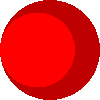

In [ ]:
from pytamaro import Graphic, Color, ellipse, pin, center_left, compose, hsv_color, show_graphic

def dot(outer_diameter: float, inner_diameter: float, outer_color: Color, inner_color: Color) -> Graphic:
    return #TODO

show_graphic(dot(100, 75, hsv_color(0, 1, 0.75), hsv_color(0, 1, 1)))

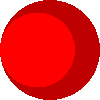

In [10]:
#teacher-only
from pytamaro import Graphic, Color, ellipse, pin, center_left, compose, hsv_color, show_graphic

def dot(outer_diameter: float, inner_diameter: float, outer_color: Color, inner_color: Color) -> Graphic:
    return compose(
        pin(center_left, ellipse(inner_diameter, inner_diameter, inner_color)),
        pin(center_left, ellipse(outer_diameter, outer_diameter, outer_color))
    )

show_graphic(dot(100, 75, hsv_color(0, 1, 0.75), hsv_color(0, 1, 1)))

### Ring

Let's create a function that can compose a ring of dots.
If you are not sure how to implement this function, check the **Sliced Pitaya** activity.

In [ ]:
from pytamaro import empty_graphic, rotate, beside, rectangle, black

def ring(count: int, ringDiameter: float, dot: Graphic) -> Graphic:
    result = empty_graphic()
    #TODO
    return result

show_graphic(ring(12, 100, dot(20, 15, hsv_color(0, 1, 0.75), hsv_color(0, 1, 1))))

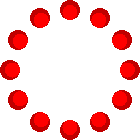

In [11]:
#teacher-only
from pytamaro import empty_graphic, rotate, beside, rectangle, black

def ring(count: int, ringDiameter: float, dot: Graphic) -> Graphic:
    result = empty_graphic()
    for i in range(count):
        angle = 360.0 / count * i
        s = rotate(
            angle,
            pin(
                center_left,
                beside(
                    rectangle(ringDiameter / 2, 0, black),
                    dot
                )
            )
        )
        result = compose(result, s)
    return result

show_graphic(ring(12, 100, dot(20, 15, hsv_color(0, 1, 0.75), hsv_color(0, 1, 1))))


### Mandala
Now let's compose a mandala from multiple concentric rings of dots.


Here is a function to compose a list of graphics.
We will use this to compose a list of concentric rings into a mandala.

In [7]:
def composes(graphics: list[Graphic]) -> Graphic:
    result = empty_graphic()
    for g in graphics:
        result = compose(result, g)
    return result

Now implement the `mandala` function below to compose a mandala like this:

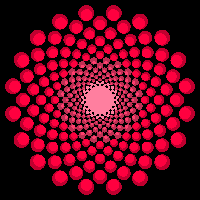

This mandala consists of 6 outer rings, 6 middle rings, 2 inner rings, and a central circle.
The outer and middle rings consist of 20 dots.
The 2 inner rings consist of 20 circles.
The color of the outer rings has a saturation of 1.0,
the middle rings of 0.75,
and the inner rings and circle of 0.5.

You can compute the diameter of the i-th ring with `largest_ring_diameter * base ** i`,
where the largest ring is the 0-th ring,
and `base` is a number smaller than 1 (e.g., 0.875).

In [ ]:
def mandala(diameter: float, hue: float) -> Graphic:
    return #TODO

show_graphic(mandala(400, 345))

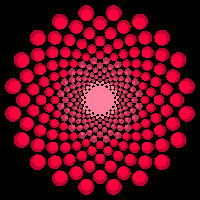

In [17]:
#teacher-only
def ro(diameter: float, rot: bool, hue: float) -> Graphic:
    return rotate(
        360 / 20 / 2 if rot else 0, 
        ring(20, diameter, dot(diameter * 0.1, diameter * 0.1 * 0.75, hsv_color(hue, 1, 0.75), hsv_color(hue, 1, 1)))
    )
def ri(diameter: float, rot: bool, hue: float) -> Graphic:
    return rotate(
        360 / 20 / 2 if rot else 0, 
        ring(20, diameter, dot(diameter * 0.1, diameter * 0.1 * 0.5, hsv_color(hue, 0.75, 0.75), hsv_color(hue, 0.75, 1)))
    )
def rc(diameter: float, rot: bool, hue: float) -> Graphic:
    return rotate(
        360 / 20 / 2 if rot else 0, 
        ring(20, diameter, ellipse(diameter * 0.1, diameter * 0.1, hsv_color(hue, 0.5, 1)))
    )

def mandala(diameter: float, hue: float) -> Graphic:
    dia = diameter * 0.8
    base = 0.875
    return composes([
        ellipse(dia * base ** 13, dia * base ** 13, hsv_color(hue, 0.5, 1)),
        rc(dia * base ** 13, False, hue),
        rc(dia * base ** 12, True, hue),
        ri(dia * base ** 11, False, hue),
        ri(dia * base ** 10, True, hue),
        ri(dia * base ** 9, False, hue),
        ri(dia * base ** 8, True, hue),
        ri(dia * base ** 7, False, hue),
        ri(dia * base ** 6, True, hue),
        ro(dia * base ** 5, False, hue),
        ro(dia * base ** 4, True, hue),
        ro(dia * base ** 3, False, hue),
        ro(dia * base ** 2, True, hue),
        ro(dia * base ** 1, False, hue),
        ro(dia * base ** 0, True, hue),
        rectangle(diameter, diameter, black)
    ])

show_graphic(mandala(200, 345))

from pytamaro import save_graphic
save_graphic("mandala-flower.svg", mandala(400, 345))
